In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
### define the glucose-insulin model and PID controller ###

# discrete time step in minutes
Dt = 5 

# glucose dynamics model, u is insulin input, g is meal glucose input
class GlucoseModel:
    def __init__(self, ini_value = 0):
        self.a1 = 2.48
        self.a2 = -2.0325
        self.a3 = 0.55125
        self.b = -0.25
        self.x = [ini_value]
        self.u = [0]
        self.g = [0]
        self.n_steps = 0

    def step(self, u_input = 0, g_input = 0):
        self.n_steps += 1
        self.u.append(u_input)
        self.g.append(g_input)
        if self.n_steps == 1:
            self.x.append(self.g[-1] + self.a1 * self.x[-1])
        elif self.n_steps == 2:
            self.x.append(self.g[-1] + self.a1 * self.x[-1] + self.a2 * self.x[-2])
        else:
            self.x.append(self.g[-1] + self.a1 * self.x[-1] + self.a2 * self.x[-2] + self.a3 * self.x[-3] + self.b * self.u[-3])

# PID controller class. Once intialized, step() takes in the current state and generates the PID control value
class PIDController:
    def __init__(self, Kp = 0, Ki = 0, Kd = 0):
        self.Kp = Kp
        self.Ki = Ki
        self.Kd = Kd
        self.err = [0, 0] # initialise with two zeros to avoid index issues
        self.u_cache = 0
    
    def step(self, y, ystar = 0, control_bounds = (-np.inf, np.inf)):
        self.err.append(ystar - y)
        dP = self.Kp * (self.err[-1] - self.err[-2])
        dI = self.Ki * self.err[-1] * Dt
        dD = self.Kd * (self.err[-1] - 2 * self.err[-2] + self.err[-3]) / Dt
        u_new = self.u_cache + (dP + dI + dD)
        u_new = np.clip(u_new, *control_bounds)
        self.u_cache = u_new
        return u_new

# two different types of disturbance pulses: a meal pulse and a constant pulse
# t0: start of the pulse; tau: decay time constant; A: amplitude
def meal_pulse(t, t0 = 60, tau = 40, A = 120, **kwargs):
    tt = np.maximum(t - t0, 0)
    return A / tau ** 2 * tt * np.exp(-tt / tau)

def cons_pulse(t, t0 = 60, A = 0.13, **kwargs):
    return A * np.tanh((t-t0) * (t >= t0) / 10)

In [4]:
### initialise parameters ###

# transfer-function–derived PID gains
tau1, tau2, tauc = 247, 26, 40
K = -200
theta = 11

Kp_opt = (tau1 + tau2) / (K * (tauc + theta))
Ki_opt = 1 / (K * (tauc + theta))
Kd_opt = (tau1 * tau2) / (K * (tauc + theta))

# Three controller parameter sets
PID_param_sets = {
    "No control":dict(Kp=0, Ki=0,Kd=0),
    "PID": dict(Kp=Kp_opt,Ki=Ki_opt,Kd=Kd_opt),
    "PD":dict(Kp=Kp_opt,Ki=0,Kd=Kd_opt),
}

# two different disturbance pulses: a meal pulse and a constant pulse
Pulse_param_sets = {
    "meal": meal_pulse,
    "constant": cons_pulse,
}

# simulation time: 24 hours * 12 steps per hour = 288 steps
Nsteps = 288

# bounds on insulin control input: non-negative
control_bounds = (0, np.inf)

In [5]:
# run simulations for both meal and constant pulses

results = np.zeros((len(Pulse_param_sets), len(PID_param_sets), Nsteps + 1, 3))  # shape: (pulse, controller, time, disturbance/glucose/insulin)
for pulse_idx, (pulse_label, pulse) in enumerate(Pulse_param_sets.items()):
    for PID_idx, (PID_label, gains) in enumerate(PID_param_sets.items()):
        model = GlucoseModel()
        ctrl = PIDController(**gains)
        u_input = 0
        for i in range(Nsteps):
            g_in = pulse(i * Dt, tau=tauc)
            model.step(u_input=u_input, g_input=g_in)
            u_input = ctrl.step(model.x[-1])
        results[pulse_idx, PID_idx] = np.array([model.g, model.x, model.u]).T   # convert to per-hour rate

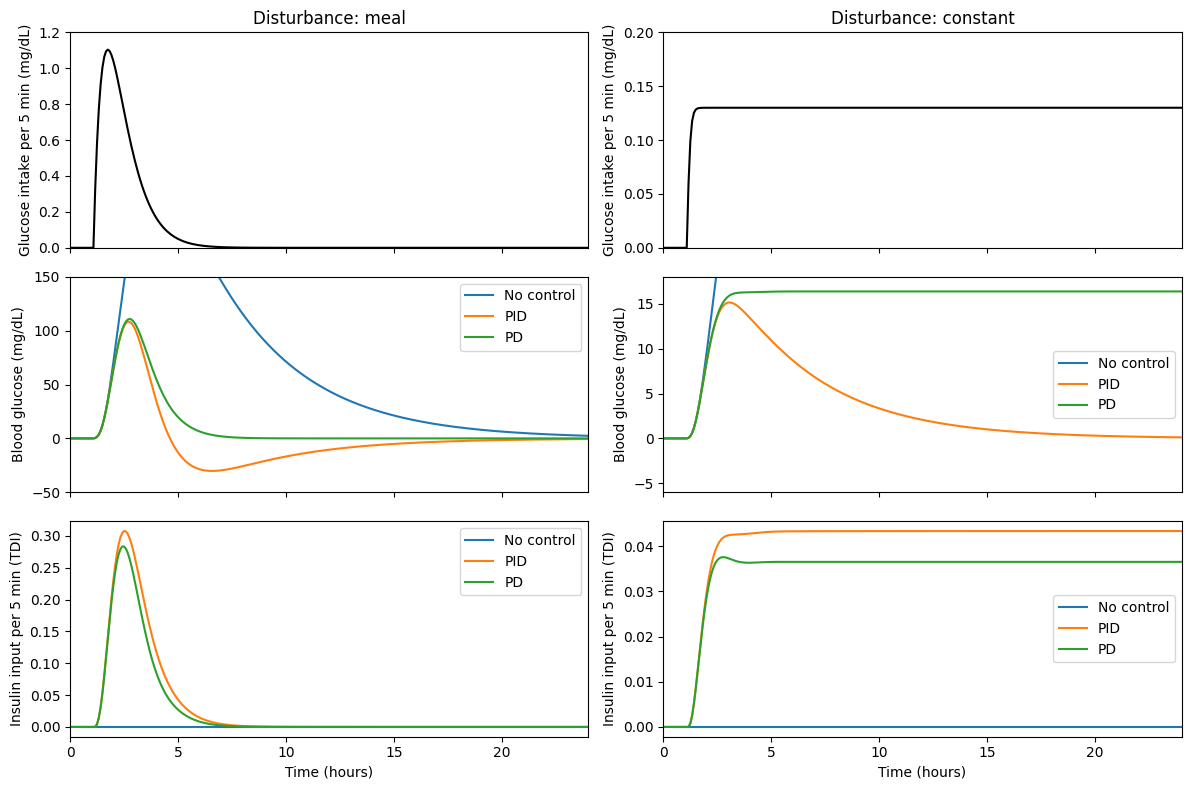

In [6]:
fig, axes = plt.subplots(3, 2, figsize=(12, 8), sharex=True)
for pulse_idx, (pulse_label, pulse) in enumerate(Pulse_param_sets.items()):
    axes[0, pulse_idx].plot(np.arange(Nsteps + 1) * Dt / 60, results[pulse_idx, 0, :, 0], color = 'black')
    axes[0, pulse_idx].set_title(f"Disturbance: {pulse_label}")
    axes[0, pulse_idx].set_ylabel("Glucose intake per 5 min (mg/dL)")
    for PID_idx, (PID_label, gains) in enumerate(PID_param_sets.items()):
        axes[1, pulse_idx].plot(np.arange(Nsteps + 1) * Dt / 60, results[pulse_idx, PID_idx, :, 1], label=PID_label)
        axes[2, pulse_idx].plot(np.arange(Nsteps + 1) * Dt / 60, results[pulse_idx, PID_idx, :, 2]/12, label=PID_label) # convert to per-5-min-rate
    axes[1, pulse_idx].legend()
    axes[2, pulse_idx].legend()
    axes[1, pulse_idx].set_ylabel("Blood glucose (mg/dL)")
    axes[2, pulse_idx].set_ylabel("Insulin input per 5 min (TDI)")

axes[0, 0].set_ylim(0, 1.2)
axes[0, 1].set_ylim(0, 0.2)
axes[0, 0].set_xlim(0, 24)
axes[1, 0].set_ylim(-50, 150)
axes[1, 1].set_ylim(-6, 18)
axes[-1, 0].set_xlabel("Time (hours)")
axes[-1, 1].set_xlabel("Time (hours)")
plt.tight_layout()
plt.savefig("artificial_pancreas.png", dpi=300)